# 232. Which Botryllus proteins match human immune genes, and HLA, with kmerseek at E ≤ 10?

**Question.** Which *Botryllus schlosseri* proteins have a kmerseek match with E-value ≤ 10
to any human immune gene, and to the HLA genes (the human MHC) in particular?

**Decision this informs.** Which Botryllus proteins go forward as MHC-like candidates for
structure comparison (Foldseek) and synteny follow-up.

**Decision rule, written before looking at the results.**

* A Botryllus protein is an MHC-like candidate if it matches an HLA gene at E ≤ 0.001 and
  the matched part of the HLA protein is the peptide-binding groove (class I α1/α2,
  class II α1/β1) or the Ig-like domain.
* HLA matches with E between 0.001 and 10 are listed but treated as chance: the E-value
  is the number of matches this good expected by chance for one query against all 19,429
  human proteins, so E = 1 means one such chance match per query, and this run has
  72,617 queries.
* A match to the HLA transmembrane helix or signal peptide alone is not MHC evidence,
  since every single-pass membrane protein has one.

**Data.**

* Tool: kmerseek 0.4.0, hydrophobic-polar alphabet `hp_lehninger2`, k = 24, scaled = 1
  (every k-mer kept). Two arms: low-complexity k-mers removed (`lcremoved`, the main
  result) and kept (`lckept`).
* Query: 72,617 Botryllus protein translations, `~/data/botryllus/Bs_proteins.fa`.
* Target database: 19,429 human GENCODE v49 canonical protein translations.
* Search output: `~/data/botryllus/kmerseek-0.4/*.scaled1.{lcremoved,lckept}.v0.4.0.bh_corrected.csv`
  (22 Sept 2026), made by the pipeline in
  [PR 10](https://github.com/olgabot/botryllus-mhc/pull/10).
* E-value column: `region_evalue`, the Karlin-Altschul E-value of the region kmerseek
  extended from the shared k-mers.
* Human immune genes: every human protein annotated by QuickGO to GO:0002376 "immune
  system process" or any term below it (2,635 gene symbols, downloaded 25 Oct 2026,
  cached in `notebooks/data/`).
* HLA genes: human gene symbols starting with `HLA-`. HLA protein parts (signal peptide,
  α1, α2, Ig-like domain, transmembrane, cytoplasmic) come from UniProt features,
  cached in `notebooks/data/uniprot_hla/`.

**Matches with an infinite E-value.** kmerseek gives E = inf when it found shared k-mers
but did not extend them into an alignment (`region_ka_bits` = 0). An E ≤ 10 filter drops
these silently, so section 5 lists them on their own.

In [1]:
import json
import re
import urllib.parse
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import pubfig as pf

pf.use_style()
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_width_chars(220)
pl.Config.set_fmt_str_lengths(60)

KMERSEEK_DIR = Path.home() / "data/botryllus/kmerseek-0.4"
ARMS = ["lcremoved", "lckept"]
MAIN_ARM = "lcremoved"
ARM_LABEL = {
    "lcremoved": "low-complexity k-mers removed",
    "lckept": "low-complexity k-mers kept",
}
TOOL_LINE = "kmerseek 0.4.0, hp_lehninger2, k = 24, scaled = 1"
QUERY_TARGET_LINE = "query: Botryllus proteins (72,617); target: human GENCODE v49 canonical (19,429)"

MAX_EVALUE = 10
STRICT_EVALUE = 1e-3
EVALUE_CUTOFFS = [10, 1, 1e-1, 1e-2, 1e-3, 1e-4, 1e-5]

DATA_DIR = Path("data")
UNIPROT_HLA_DIR = DATA_DIR / "uniprot_hla"
OUT_DIR = Path("232_outputs")
FIG_DIR = Path("../figures/232")
for d in (DATA_DIR, UNIPROT_HLA_DIR, OUT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

GO_IMMUNE_TSV = DATA_DIR / "go0002376_immune_system_process_human_quickgo.tsv"
QUICKGO_URL = (
    "https://www.ebi.ac.uk/QuickGO/services/annotation/downloadSearch?"
    "goId=GO:0002376&goUsage=descendants&goUsageRelationships=is_a,part_of,occurs_in"
    "&taxonId=9606&taxonUsage=exact&geneProductType=protein&selectedFields=symbol,goId"
    "&downloadLimit=2000000"
)


def kmerseek_csv(arm: str) -> Path:
    """Path of one arm's full kmerseek search table (all hits, before any filter)."""
    return KMERSEEK_DIR / (
        f"kmerseek-botryllus-vs-human-gencode.canonical.v49.hp_lehninger2.k24.scaled1.{arm}.v0.4.0.bh_corrected.csv"
    )

## 1. Human immune gene list (GO:0002376 and the terms below it)

In [2]:
if not GO_IMMUNE_TSV.exists():
    req = urllib.request.Request(QUICKGO_URL, headers={"Accept": "text/tsv"})
    GO_IMMUNE_TSV.write_bytes(urllib.request.urlopen(req, timeout=300).read())
go_immune = pl.read_csv(GO_IMMUNE_TSV, separator="\t")
assert go_immune.columns == ["SYMBOL", "GO TERM"], go_immune.columns  # not an outage page
immune_genes = sorted(set(go_immune["SYMBOL"]))
hla_genes_in_go = [g for g in immune_genes if g.startswith("HLA-")]
print(f"{len(go_immune):_} GO annotations, {len(immune_genes):_} human immune gene symbols, "
      f"{len(hla_genes_in_go)} of them start with HLA- (many are allele names from unreviewed entries)")

12_125 GO annotations, 2_634 human immune gene symbols, 107 of them start with HLA- (many are allele names from unreviewed entries)


## 2. All kmerseek matches from Botryllus proteins to human immune genes

Every row is one Botryllus protein region matched to one human protein region. Kept: the
human gene is in the immune list, and the E-value is at most 10 or is infinite (not
extended). Reading the 2.6 and 3.4 GB tables takes about a minute each.

In [3]:
KEEP_COLUMNS = [
    "query_name", "human_gene", "human_protein_length", "region_evalue", "region_ka_bits",
    "region_tail_probability_bh", "region_length", "region_n_shared_kmers",
    "region_start", "region_end", "target_start", "target_end", "region_subseq", "target_subseq",
]


def immune_matches(arm: str) -> tuple[pl.DataFrame, dict]:
    """Matches to immune genes with E <= MAX_EVALUE or E = inf, plus whole-table counts."""
    lf = pl.scan_csv(kmerseek_csv(arm), infer_schema_length=10_000).with_columns(
        pl.col("query_name").str.strip_chars(),
        pl.col("target_name").str.split("|").list.get(6).alias("human_gene"),
        pl.col("target_name").str.split("|").list.get(7).cast(pl.Int64).alias("human_protein_length"),
    )
    counts = lf.select(
        pl.len().alias("all_matches"),
        (pl.col("region_evalue") <= MAX_EVALUE).sum().alias("matches_e_le_10"),
        pl.col("region_evalue").is_infinite().sum().alias("matches_e_inf"),
        # inf E-value must mean "not extended" (KA bits = 0) and nothing else
        (pl.col("region_evalue").is_infinite() != (pl.col("region_ka_bits") == 0)).sum().alias("inf_e_without_zero_bits"),
    ).collect(engine="streaming").row(0, named=True)
    df = (
        lf.filter(
            pl.col("human_gene").is_in(immune_genes)
            & ((pl.col("region_evalue") <= MAX_EVALUE) | pl.col("region_evalue").is_infinite())
        )
        .select(KEEP_COLUMNS)
        .collect(engine="streaming")
        .with_columns(
            pl.lit(arm).alias("arm"),
            pl.col("human_gene").str.starts_with("HLA-").alias("is_hla"),
            pl.col("region_evalue").is_infinite().alias("not_extended"),
        )
    )
    return df, counts


matches, whole_table = {}, {}
for arm in ARMS:
    matches[arm], whole_table[arm] = immune_matches(arm)
    assert whole_table[arm]["inf_e_without_zero_bits"] == 0
whole_table_df = pl.DataFrame([{"arm": a, **whole_table[a]} for a in ARMS])
print("Whole search tables (all human genes):")
print(whole_table_df)

Whole search tables (all human genes):
shape: (2, 5)
┌───────────┬─────────────┬─────────────────┬───────────────┬─────────────────────────┐
│ arm       ┆ all_matches ┆ matches_e_le_10 ┆ matches_e_inf ┆ inf_e_without_zero_bits │
│ ---       ┆ ---         ┆ ---             ┆ ---           ┆ ---                     │
│ str       ┆ i64         ┆ i64             ┆ i64           ┆ i64                     │
╞═══════════╪═════════════╪═════════════════╪═══════════════╪═════════════════════════╡
│ lcremoved ┆ 3516235     ┆ 403551          ┆ 8106          ┆ 0                       │
│ lckept    ┆ 4504849     ┆ 248229          ┆ 68070         ┆ 0                       │
└───────────┴─────────────┴─────────────────┴───────────────┴─────────────────────────┘


## 3. How many Botryllus proteins match an immune gene, at each E-value cut-off

Lower E is stronger. The count at E ≤ 10 is the answer to the question as asked; the
counts at stricter cut-offs show how much of it survives once chance matches are
removed.

In [4]:
def count_by_cutoff(df: pl.DataFrame, arm: str) -> pl.DataFrame:
    """Matches, Botryllus proteins and human genes at each E cut-off, HLA and all immune."""
    rows = []
    extended = df.filter(~pl.col("not_extended"))
    for cutoff in EVALUE_CUTOFFS:
        for gene_set, sub in [("all immune genes", extended), ("HLA genes", extended.filter("is_hla"))]:
            hit = sub.filter(pl.col("region_evalue") <= cutoff)
            rows.append({
                "arm": arm, "gene_set": gene_set, "max_evalue": cutoff, "n_matches": len(hit),
                "n_botryllus_proteins": hit["query_name"].n_unique(),
                "n_human_genes": hit["human_gene"].n_unique(),
            })
    return pl.DataFrame(rows)


cutoff_counts = pl.concat([count_by_cutoff(matches[a], a) for a in ARMS])
cutoff_counts.write_csv(OUT_DIR / "232_immune_match_counts_by_evalue_kmerseek_botryllus_vs_gencode.csv")
print(cutoff_counts)

shape: (28, 6)
┌───────────┬──────────────────┬────────────┬───────────┬──────────────────────┬───────────────┐
│ arm       ┆ gene_set         ┆ max_evalue ┆ n_matches ┆ n_botryllus_proteins ┆ n_human_genes │
│ ---       ┆ ---              ┆ ---        ┆ ---       ┆ ---                  ┆ ---           │
│ str       ┆ str              ┆ f64        ┆ i64       ┆ i64                  ┆ i64           │
╞═══════════╪══════════════════╪════════════╪═══════════╪══════════════════════╪═══════════════╡
│ lcremoved ┆ all immune genes ┆ 10.0       ┆ 30509     ┆ 19733                ┆ 1648          │
│ lcremoved ┆ HLA genes        ┆ 10.0       ┆ 235       ┆ 170                  ┆ 19            │
│ lcremoved ┆ all immune genes ┆ 1.0        ┆ 4232      ┆ 2466                 ┆ 848           │
│ lcremoved ┆ HLA genes        ┆ 1.0        ┆ 11        ┆ 10                   ┆ 4             │
│ lcremoved ┆ all immune genes ┆ 0.1        ┆ 2076      ┆ 1087                 ┆ 442           │
│ lcremoved ┆ H

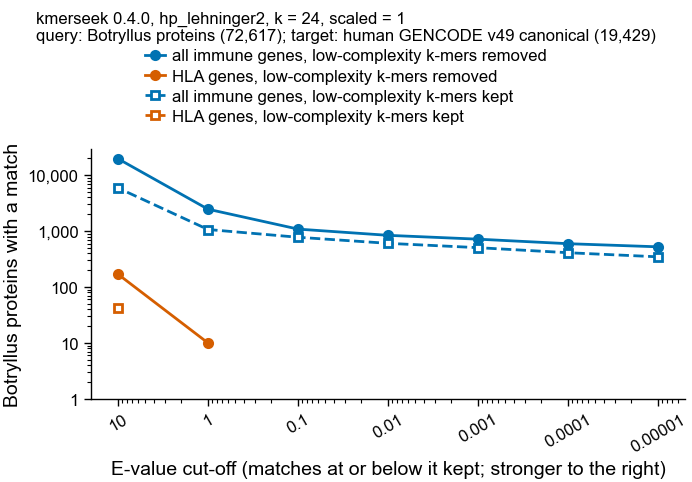

In [5]:
GENE_SET_COLOUR = {"all immune genes": pf.OKABE_ITO["blue"], "HLA genes": pf.OKABE_ITO["vermillion"]}
ARM_MARKER = {"lcremoved": "o", "lckept": "s"}
ARM_FILL = {"lcremoved": True, "lckept": False}

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 62)
for arm in ARMS:
    for gene_set, colour in GENE_SET_COLOUR.items():
        sub = cutoff_counts.filter((pl.col("arm") == arm) & (pl.col("gene_set") == gene_set)).sort("max_evalue")
        sub = sub.filter(pl.col("n_botryllus_proteins") > 0)
        ax.plot(sub["max_evalue"], sub["n_botryllus_proteins"], color=colour,
                marker=ARM_MARKER[arm], markerfacecolor=colour if ARM_FILL[arm] else "white",
                linestyle="-" if ARM_FILL[arm] else "--",
                label=f"{gene_set}, {ARM_LABEL[arm]}")
ax.set_xscale("log")
ax.set_yscale("log")
ax.invert_xaxis()
ax.set_xticks(EVALUE_CUTOFFS, ["10", "1", "0.1", "0.01", "0.001", "0.0001", "0.00001"], rotation=30)
ax.set_yticks([1, 10, 100, 1_000, 10_000], ["1", "10", "100", "1,000", "10,000"])
ax.set_xlabel("E-value cut-off (matches at or below it kept; stronger to the right)")
ax.set_ylabel("Botryllus proteins with a match")
pf.shared_legend(fig, ncol=1, title=f"{TOOL_LINE}\n{QUERY_TARGET_LINE}")
pf.save(fig, FIG_DIR / "232a_botryllus_proteins_matching_human_immune_genes_by_evalue_kmerseek")
plt.show()

How to read it: each line follows one gene set from the loose cut-off (E ≤ 10, left) to
strict ones (right). The vermillion HLA lines stop where no HLA match is left. The blue
lines fall slowly because some matches are to well-conserved proteins that GO also
files under immune processes (section 4).

## 4. The HLA matches: how strong, and which part of the HLA protein

The part of the HLA protein covered by each match comes from UniProt features (signal
peptide, peptide-binding groove, Ig-like domain, transmembrane helix, cytoplasmic tail).
Each match is assigned the part that covers most of its human residues. Before using
UniProt positions on GENCODE proteins, the protein lengths are compared.

In [6]:
CLASS_I = {"HLA-A", "HLA-B", "HLA-C", "HLA-E", "HLA-F", "HLA-G"}


def uniprot_hla(gene: str) -> dict:
    """Reviewed human UniProt entry for one HLA gene, cached as JSON."""
    path = UNIPROT_HLA_DIR / f"{gene}.json"
    if not path.exists():
        query = f"gene_exact:{gene} AND organism_id:9606 AND reviewed:true"
        url = ("https://rest.uniprot.org/uniprotkb/search?format=json&fields=accession,gene_primary,"
               "length,ft_transmem,ft_domain,ft_signal,ft_region,ft_topo_dom&query=" + urllib.parse.quote(query))
        path.write_bytes(urllib.request.urlopen(url, timeout=120).read())
    results = json.loads(path.read_text())["results"]
    assert len(results) == 1, (gene, len(results))
    return results[0]


def hla_part_by_residue(entry: dict, gene: str) -> list[str]:
    """Name of the HLA protein part at each residue (index 0 = residue 1)."""
    length = entry["sequence"]["length"]
    part = ["other"] * length
    groove = {"Alpha-1", "Beta-1"} | ({"Alpha-2"} if gene in CLASS_I else set())
    # later layers win: groove, then Ig-like, then cytoplasmic, signal and transmembrane
    layers = [
        ("peptide-binding groove", lambda f: f["type"] == "Region" and f.get("description") in groove),
        ("Ig-like domain", lambda f: f["type"] == "Domain" and f.get("description", "").startswith("Ig-like")),
        ("cytoplasmic tail", lambda f: f["type"] == "Topological domain" and f.get("description") == "Cytoplasmic"),
        ("signal peptide", lambda f: f["type"] == "Signal"),
        ("transmembrane helix", lambda f: f["type"] == "Transmembrane"),
    ]
    for name, keep in layers:
        for f in entry["features"]:
            if keep(f):
                start, end = f["location"]["start"]["value"], f["location"]["end"]["value"]
                for i in range(start - 1, end):
                    part[i] = name
    return part


hla_matches = pl.concat([matches[a].filter(pl.col("is_hla") & ~pl.col("not_extended")) for a in ARMS])
hla_part_lookup, length_check = {}, []
for gene in sorted(hla_matches["human_gene"].unique()):
    entry = uniprot_hla(gene)
    hla_part_lookup[gene] = hla_part_by_residue(entry, gene)
    gencode_length = hla_matches.filter(pl.col("human_gene") == gene)["human_protein_length"][0]
    length_check.append({"human_gene": gene, "uniprot": entry["primaryAccession"],
                         "uniprot_length": entry["sequence"]["length"], "gencode_length": gencode_length})
length_check = pl.DataFrame(length_check).with_columns(
    (pl.col("uniprot_length") == pl.col("gencode_length")).alias("same_length"))
print(length_check)


NOT_MAPPED = "not mapped (GENCODE isoform length differs from UniProt)"
same_length = dict(zip(length_check["human_gene"], length_check["same_length"]))


def main_part(gene: str, target_start: int, target_end: int) -> str:
    """HLA part covering most residues of a match (target_start 0-based, target_end exclusive)."""
    if not same_length[gene]:
        return NOT_MAPPED
    parts = hla_part_lookup[gene][target_start:target_end]
    # a tie goes to the part that comes first along the protein, so reruns agree
    return max(dict.fromkeys(parts), key=parts.count)


hla_matches = hla_matches.with_columns(
    pl.struct("human_gene", "target_start", "target_end")
    .map_elements(lambda r: main_part(r["human_gene"], r["target_start"], r["target_end"]), return_dtype=pl.Utf8)
    .alias("hla_part_matched"),
    pl.when(pl.col("human_gene").is_in(list(CLASS_I))).then(pl.lit("class I")).otherwise(pl.lit("class II"))
    .alias("hla_class"),
)
hla_matches.sort("arm", "region_evalue").write_csv(
    OUT_DIR / "232_hla_matches_evalue_le_10_kmerseek_botryllus_vs_gencode.csv")

shape: (19, 5)
┌────────────┬─────────┬────────────────┬────────────────┬─────────────┐
│ human_gene ┆ uniprot ┆ uniprot_length ┆ gencode_length ┆ same_length │
│ ---        ┆ ---     ┆ ---            ┆ ---            ┆ ---         │
│ str        ┆ str     ┆ i64            ┆ i64            ┆ bool        │
╞════════════╪═════════╪════════════════╪════════════════╪═════════════╡
│ HLA-A      ┆ P04439  ┆ 365            ┆ 365            ┆ true        │
│ HLA-B      ┆ P01889  ┆ 362            ┆ 362            ┆ true        │
│ HLA-C      ┆ P10321  ┆ 366            ┆ 366            ┆ true        │
│ HLA-DMA    ┆ P28067  ┆ 261            ┆ 261            ┆ true        │
│ HLA-DMB    ┆ P28068  ┆ 263            ┆ 263            ┆ true        │
│ HLA-DOA    ┆ P06340  ┆ 250            ┆ 250            ┆ true        │
│ HLA-DOB    ┆ P13765  ┆ 273            ┆ 273            ┆ true        │
│ HLA-DPA1   ┆ P20036  ┆ 260            ┆ 260            ┆ true        │
│ HLA-DPB1   ┆ P04440  ┆ 258        

In [7]:
hla_main = hla_matches.filter(pl.col("arm") == MAIN_ARM)
print(f"{ARM_LABEL[MAIN_ARM]}: {len(hla_main)} HLA matches, "
      f"{hla_main['query_name'].n_unique()} Botryllus proteins, {hla_main['human_gene'].n_unique()} HLA genes; "
      f"strongest E = {hla_main['region_evalue'].min():.3f}; matches at E <= {STRICT_EVALUE}: "
      f"{hla_main.filter(pl.col('region_evalue') <= STRICT_EVALUE).height}")
print("\nHLA part matched, both arms:")
part_counts = (hla_matches.group_by("arm", "hla_part_matched").agg(pl.len().alias("n_matches"))
               .sort("arm", "n_matches", descending=[False, True]))
print(part_counts)
print("\nBest match per HLA gene:")
best_per_hla = (hla_main.sort("region_evalue").group_by("human_gene", maintain_order=True)
                .agg(pl.len().alias("n_matches"), pl.col("query_name").n_unique().alias("n_botryllus_proteins"),
                     pl.col("region_evalue").first().alias("best_evalue"),
                     pl.col("query_name").first().alias("best_botryllus_protein"),
                     pl.col("hla_part_matched").first().alias("part_matched_by_best")))
print(best_per_hla)

low-complexity k-mers removed: 235 HLA matches, 170 Botryllus proteins, 19 HLA genes; strongest E = 0.127; matches at E <= 0.001: 0

HLA part matched, both arms:
shape: (12, 3)
┌───────────┬──────────────────────────────────────────────────────────┬───────────┐
│ arm       ┆ hla_part_matched                                         ┆ n_matches │
│ ---       ┆ ---                                                      ┆ ---       │
│ str       ┆ str                                                      ┆ u32       │
╞═══════════╪══════════════════════════════════════════════════════════╪═══════════╡
│ lckept    ┆ transmembrane helix                                      ┆ 23        │
│ lckept    ┆ Ig-like domain                                           ┆ 15        │
│ lckept    ┆ peptide-binding groove                                   ┆ 8         │
│ lckept    ┆ not mapped (GENCODE isoform length differs from UniProt) ┆ 6         │
│ lckept    ┆ cytoplasmic tail                            

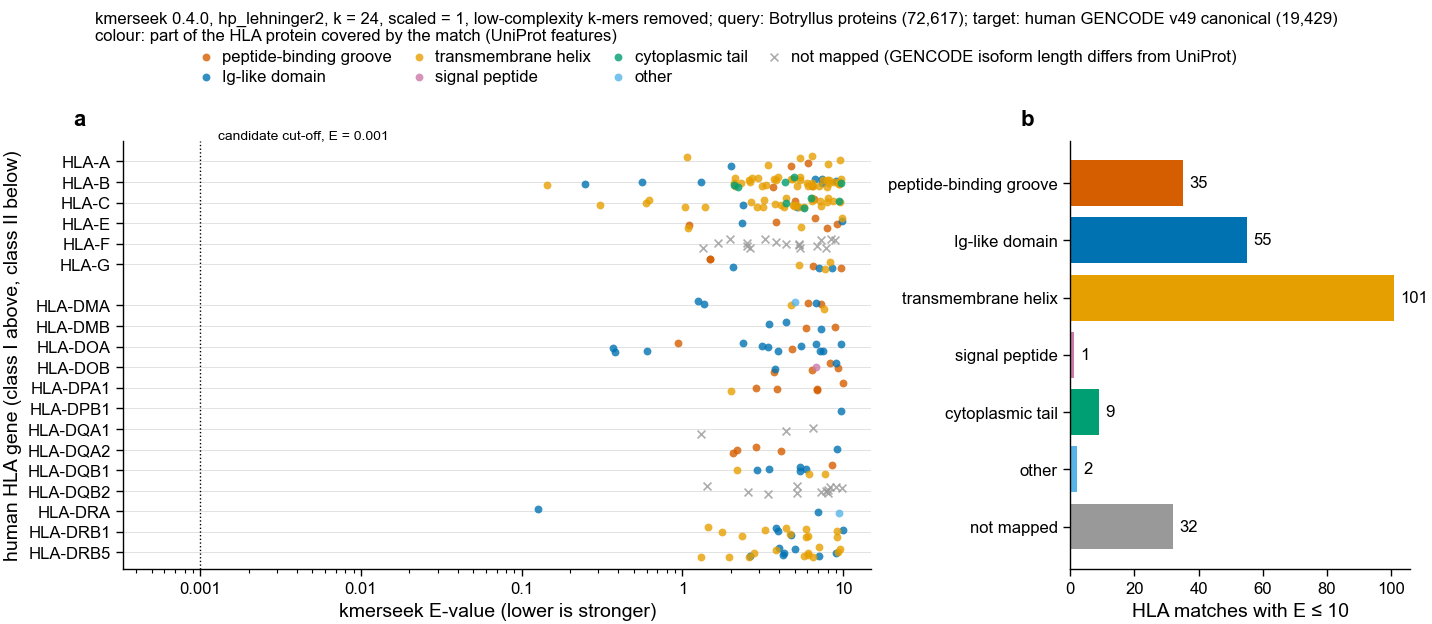

In [8]:
PART_COLOUR = {
    "peptide-binding groove": pf.OKABE_ITO["vermillion"],
    "Ig-like domain": pf.OKABE_ITO["blue"],
    "transmembrane helix": pf.OKABE_ITO["orange"],
    "signal peptide": pf.OKABE_ITO["reddish_purple"],
    "cytoplasmic tail": pf.OKABE_ITO["bluish_green"],
    "other": pf.OKABE_ITO["sky_blue"],
    NOT_MAPPED: pf.GREY,
}
PART_MARKER = {part: ("x" if part == NOT_MAPPED else "o") for part in PART_COLOUR}
assert set(hla_matches["hla_part_matched"]) <= set(PART_COLOUR), set(hla_matches["hla_part_matched"])

gene_order = (best_per_hla.with_columns(pl.col("human_gene").is_in(list(CLASS_I)).alias("class_i"))
              .sort("class_i", "human_gene", descending=[True, False])["human_gene"].to_list())
# a gap between class I and class II rows
y_of_gene, y = {}, 0
for gene in gene_order:
    if y_of_gene and gene not in CLASS_I and all(g in CLASS_I for g in y_of_gene):
        y += 1
    y_of_gene[gene] = y
    y += 1

fig, (ax_a, ax_b) = pf.figure(pf.TWO_COLUMN_MM, 80, ncols=2, gridspec_kw={"width_ratios": [2.2, 1]})
rng = np.random.default_rng(0)
for part, colour in PART_COLOUR.items():
    sub = hla_main.filter(pl.col("hla_part_matched") == part)
    if len(sub) == 0:
        continue
    ys = np.array([y_of_gene[g] for g in sub["human_gene"]]) + rng.uniform(-0.25, 0.25, len(sub))
    ax_a.scatter(sub["region_evalue"], ys, color=colour, s=8, alpha=0.8, marker=PART_MARKER[part],
                 linewidths=0 if PART_MARKER[part] == "o" else 0.6, label=part)
for gene, yy in y_of_gene.items():
    ax_a.axhline(yy, color="#dddddd", linewidth=0.3, zorder=0)
ax_a.axvline(STRICT_EVALUE, color="black", linewidth=0.5, linestyle=":")
ax_a.text(STRICT_EVALUE * 1.3, -0.9, f"candidate cut-off, E = {STRICT_EVALUE:g}", fontsize=5, va="bottom")
ax_a.set_xscale("log")
ax_a.set_xlim(STRICT_EVALUE / 3, MAX_EVALUE * 1.5)
ax_a.set_xticks([1e-3, 1e-2, 1e-1, 1, 10], ["0.001", "0.01", "0.1", "1", "10"])
ax_a.set_yticks(list(y_of_gene.values()), list(y_of_gene.keys()))
ax_a.set_ylim(max(y_of_gene.values()) + 0.8, -1)
ax_a.set_xlabel("kmerseek E-value (lower is stronger)")
ax_a.set_ylabel("human HLA gene (class I above, class II below)")

counts_main = part_counts.filter(pl.col("arm") == MAIN_ARM)
parts_present = [p for p in PART_COLOUR if p in set(counts_main["hla_part_matched"])]
n_by_part = dict(zip(counts_main["hla_part_matched"], counts_main["n_matches"]))
ax_b.barh(range(len(parts_present)), [n_by_part[p] for p in parts_present],
          color=[PART_COLOUR[p] for p in parts_present])
for i, p in enumerate(parts_present):
    ax_b.text(n_by_part[p] + 2, i, str(n_by_part[p]), va="center", fontsize=6)
ax_b.set_yticks(range(len(parts_present)), [p.split(" (")[0] for p in parts_present])
ax_b.invert_yaxis()
ax_b.set_xlabel("HLA matches with E ≤ 10")
pf.shared_legend(fig, ncol=4, title=f"{TOOL_LINE}, {ARM_LABEL[MAIN_ARM]}; {QUERY_TARGET_LINE}\n"
                 "colour: part of the HLA protein covered by the match (UniProt features)")
for ax, letter in zip((ax_a, ax_b), "ab"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG_DIR / "232b_hla_matches_evalue_and_part_kmerseek_botryllus_vs_gencode")
plt.show()

How to read it: in panel a each dot is one Botryllus protein region matched to one HLA
protein; further left is stronger. No dot reaches the dotted candidate cut-off. Panel b
counts the same dots by which part of the HLA protein they cover.

The residues of the 10 strongest HLA matches, Botryllus first and human second:

In [9]:
top_hla = hla_main.sort("region_evalue").head(10)
for r in top_hla.iter_rows(named=True):
    print(f"{r['query_name']:<20} vs {r['human_gene']:<9} E = {r['region_evalue']:.3f}  "
          f"human residues {r['target_start'] + 1}-{r['target_end']} ({r['hla_part_matched']})")
    print(f"  Botryllus {r['region_subseq']}")
    print(f"  human     {r['target_subseq']}\n")

g564.t1 frame:1      vs HLA-DRA   E = 0.127  human residues 81-158 (Ig-like domain)
  Botryllus MTVIGVQVLAQKVSIRALTCSRRLRLVDQGLLDQSEAVRNVVKTELLQAWLRTYQVLEKLDAIGSYETTRKAVQAMFD
  human     AQGALANIAVDKANLEIMTKRSNYTPITNVPPEVTVLTNSPVELREPNVLICFIDKFTPPVVNVTWLRNGKPVTTGVS

g30570.t1 frame:3    vs HLA-B     E = 0.144  human residues 281-334 (transmembrane helix)
  Botryllus GTGSVDTSAVTKVSQGKPSRRKSTNAGLIAGVVIAVLLALLVLVVVVVVLYRRR
  human     YTCHVQHEGLPKPLTLRWEPSSQSTVPIVGIVAGLAVLAVVVIGAVVAAVMCRR

g65873.t1 frame:1    vs HLA-B     E = 0.248  human residues 245-338 (Ig-like domain)
  Botryllus PTDYSDSRNGVARIDITNRTPGKLYIVCMMESSKDIADLTIEDCEFVETNSASPGQIHDNEAIVPVWLAILIALLVILVLAAIVLVVYCQRLNA
  human     GEDQTQDTELVETRPAGDRTFQKWAAVVVPSGEEQRYTCHVQHEGLPKPLTLRWEPSSQSTVPIVGIVAGLAVLAVVVIGAVVAAVMCRRKSSG

g12602.t1 frame:2    vs HLA-C     E = 0.308  human residues 304-353 (transmembrane helix)
  Botryllus INALVIVIPIVIGVVLLGIIALILWKLYTIRRDKRLWDEFEKERMLSNCT
  human     PTIPIMGIVAGLAVLVVLAVLGAVVTAMMCRRKSSGGKGGSCS

## 5. Matches kmerseek did not extend (E-value = inf)

These matches have shared k-mers but no extended alignment, so no E-value. They are
ranked here by `region_tail_probability_bh`, the chance of this many shared k-mers in the
region, corrected for the number of tests (Benjamini-Hochberg); lower is stronger.

In [10]:
not_extended = pl.concat([matches[a].filter("not_extended") for a in ARMS]).sort("arm", "region_tail_probability_bh")
not_extended.write_csv(OUT_DIR / "232_immune_matches_not_extended_kmerseek_botryllus_vs_gencode.csv")
print(not_extended.group_by("arm").agg(pl.len().alias("n_matches"), pl.col("is_hla").sum().alias("n_hla"),
      pl.col("human_gene").unique().sort().str.join(", ").alias("human_genes")))
print(not_extended.select("arm", "query_name", "human_gene", "region_tail_probability_bh",
                          "region_n_shared_kmers", "region_subseq", "target_subseq"))

shape: (2, 4)
┌───────────┬───────────┬───────┬────────────────────┐
│ arm       ┆ n_matches ┆ n_hla ┆ human_genes        │
│ ---       ┆ ---       ┆ ---   ┆ ---                │
│ str       ┆ u32       ┆ u32   ┆ str                │
╞═══════════╪═══════════╪═══════╪════════════════════╡
│ lckept    ┆ 41        ┆ 0     ┆ ACIN1, MT1G, TNIP3 │
│ lcremoved ┆ 33        ┆ 0     ┆ ACIN1, MT1G, TNIP3 │
└───────────┴───────────┴───────┴────────────────────┘
shape: (74, 7)
┌───────────┬───────────────────┬────────────┬────────────────────────────┬───────────────────────┬────────────────────────────────────────────────────────────┬───────────────────────────────────────────────────────────┐
│ arm       ┆ query_name        ┆ human_gene ┆ region_tail_probability_bh ┆ region_n_shared_kmers ┆ region_subseq                                              ┆ target_subseq                                             │
│ ---       ┆ ---               ┆ ---        ┆ ---                        ┆ ---          

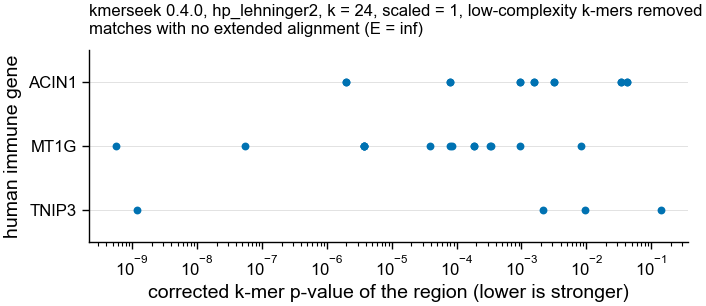

In [11]:
ne_main = not_extended.filter(pl.col("arm") == MAIN_ARM)
genes = sorted(ne_main["human_gene"].unique())
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 40)
for i, gene in enumerate(genes):
    sub = ne_main.filter(pl.col("human_gene") == gene)
    ax.scatter(sub["region_tail_probability_bh"], np.full(len(sub), i), color=pf.OKABE_ITO["blue"], s=8, linewidths=0)
    ax.axhline(i, color="#dddddd", linewidth=0.3, zorder=0)
ax.set_xscale("log")
ax.set_yticks(range(len(genes)), genes)
ax.set_ylim(len(genes) - 0.5, -0.5)
ax.set_xlabel("corrected k-mer p-value of the region (lower is stronger)")
ax.set_ylabel("human immune gene")
ax.set_title(f"{TOOL_LINE}, {ARM_LABEL[MAIN_ARM]}\nmatches with no extended alignment (E = inf)", fontsize=6, loc="left")
pf.save(fig, FIG_DIR / "232c_immune_matches_not_extended_kmerseek_botryllus_vs_gencode")
plt.show()

## 6. The strongest matches to well-known immune gene families

GO:0002376 includes many proteins that work in every cell (tubulins, proteasome subunits,
heat-shock proteins), and these give the strongest matches overall. To see immune
families a biologist would name first, this section keeps a hand-picked list of gene
symbol patterns: HLA, antigen processing (TAP, TAPBP, B2M, immunoproteasome PSMB8/9/10),
Toll-like and NOD-like receptors, complement, interleukins, chemokines and their
receptors, interferons, TNF family, NF-κB, IRF, TRAF, JAK/STAT, lymphocyte kinases (LCK,
ZAP70, SYK, BTK), CD antigens, KIR/LILR, Fc receptors, immunoglobulin and T-cell receptor
genes, RAG and AIRE.

In [12]:
KNOWN_IMMUNE_FAMILY_PATTERN = (
    r"^(HLA-|B2M$|TAP[12]$|TAPBP|PSMB(8|9|10)$|TLR\d|NLR|NOD[12]$|C[1-9][A-Z]?\d?$|CF[BDHI]$|MASP|"
    r"IL\d|IL\d+R|CCL\d|CXCL\d|CCR\d|CXCR\d|IFN[ABGLKWE]|TNF$|TNFSF|TNFRSF|LTA$|LTB$|NFKB|REL[AB]?$|IRF\d|TRAF\d|MYD88|IRAK\d|"
    r"JAK\d|STAT\d|LCK$|ZAP70|SYK$|BTK$|CD\d|KIR\d|LILR|FCGR|FCER|IG[HKL][VCDJ]|TR[ABGD][VCJ]|RAG[12]$|AIRE$|CARD11$)"
)
known = matches[MAIN_ARM].filter(~pl.col("not_extended") & pl.col("human_gene").str.contains(KNOWN_IMMUNE_FAMILY_PATTERN))
best_known = (known.sort("region_evalue").group_by("human_gene", maintain_order=True)
              .agg(pl.len().alias("n_matches"), pl.col("region_evalue").first().alias("best_evalue"),
                   pl.col("query_name").first().alias("best_botryllus_protein"),
                   pl.col("region_length").first().alias("best_region_length_aa"),
                   pl.col("region_subseq").first().alias("botryllus_residues"),
                   pl.col("target_subseq").first().alias("human_residues")))
best_known.write_csv(OUT_DIR / "232_best_match_per_known_immune_gene_kmerseek_botryllus_vs_gencode.csv")
print(f"{best_known.height} known-family immune genes with a match at E <= 10; "
      f"{best_known.filter(pl.col('best_evalue') <= STRICT_EVALUE).height} at E <= {STRICT_EVALUE}")
print(best_known.head(25).drop("botryllus_residues", "human_residues"))

336 known-family immune genes with a match at E <= 10; 9 at E <= 0.001
shape: (25, 5)
┌────────────┬───────────┬─────────────┬────────────────────────┬───────────────────────┐
│ human_gene ┆ n_matches ┆ best_evalue ┆ best_botryllus_protein ┆ best_region_length_aa │
│ ---        ┆ ---       ┆ ---         ┆ ---                    ┆ ---                   │
│ str        ┆ u32       ┆ f64         ┆ str                    ┆ i64                   │
╞════════════╪═══════════╪═════════════╪════════════════════════╪═══════════════════════╡
│ LCK        ┆ 27        ┆ 2.0283e-13  ┆ g37803.t1 frame:1      ┆ 174                   │
│ PSMB8      ┆ 6         ┆ 3.4725e-12  ┆ g69985.t1 frame:2      ┆ 201                   │
│ ZAP70      ┆ 9         ┆ 1.0424e-8   ┆ g62731.t1 frame:2      ┆ 164                   │
│ SYK        ┆ 30        ┆ 2.3504e-7   ┆ g62731.t1 frame:2      ┆ 173                   │
│ PSMB10     ┆ 8         ┆ 0.000002    ┆ g29492.t1 frame:1      ┆ 132                   │
│ TAP2       ┆

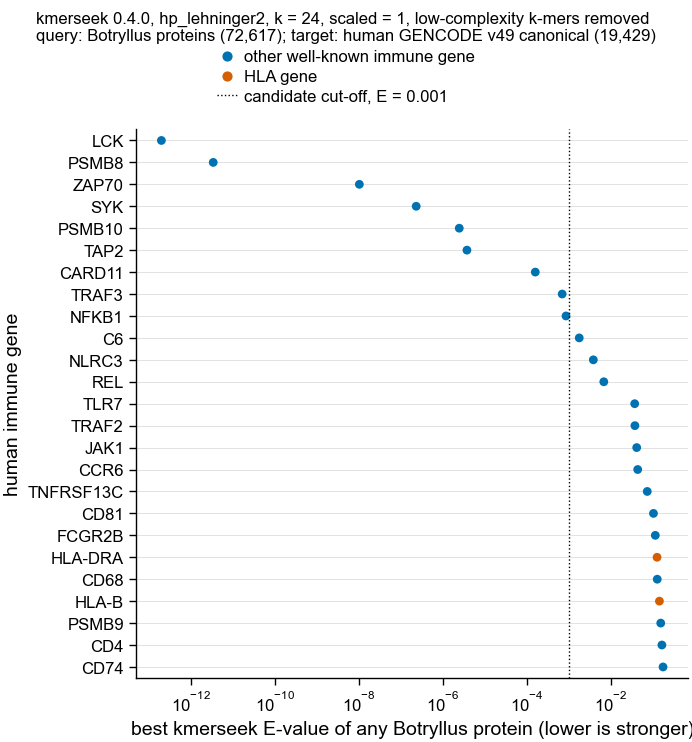

In [13]:
show = best_known.head(25)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 95)
is_hla = show["human_gene"].str.starts_with("HLA-").to_list()
ax.scatter(show["best_evalue"], range(len(show)),
           color=[pf.OKABE_ITO["vermillion"] if h else pf.OKABE_ITO["blue"] for h in is_hla], s=10, linewidths=0)
for i in range(len(show)):
    ax.axhline(i, color="#dddddd", linewidth=0.3, zorder=0)
ax.axvline(STRICT_EVALUE, color="black", linewidth=0.5, linestyle=":")
ax.set_xscale("log")
ax.set_yticks(range(len(show)), show["human_gene"].to_list())
ax.set_ylim(len(show) - 0.5, -0.5)
ax.set_xlabel("best kmerseek E-value of any Botryllus protein (lower is stronger)")
ax.set_ylabel("human immune gene")
ax.scatter([], [], color=pf.OKABE_ITO["blue"], s=10, label="other well-known immune gene")
ax.scatter([], [], color=pf.OKABE_ITO["vermillion"], s=10, label="HLA gene")
ax.plot([], [], color="black", linewidth=0.5, linestyle=":", label=f"candidate cut-off, E = {STRICT_EVALUE:g}")
pf.shared_legend(fig, ncol=1, title=f"{TOOL_LINE}, {ARM_LABEL[MAIN_ARM]}\n{QUERY_TARGET_LINE}")
pf.save(fig, FIG_DIR / "232d_best_match_per_known_immune_gene_kmerseek_botryllus_vs_gencode")
plt.show()

## Summary and conclusions

Tool for every number below: kmerseek 0.4.0, `hp_lehninger2`, k = 24, scaled = 1, low-complexity
k-mers removed, unless the other arm is named. Query: 72,617 Botryllus proteins. Target: 19,429
human GENCODE v49 canonical proteins.

1. **At E ≤ 10, 19,733 Botryllus proteins match 1,648 human immune genes (30,509 matches).** Most
   of these are chance: at E ≤ 0.001 the count falls to 718 Botryllus proteins and 341 immune genes.
   With low-complexity k-mers kept, the counts are 5,924 proteins at E ≤ 10 and 506 at E ≤ 0.001.

2. **170 Botryllus proteins match 19 HLA genes at E ≤ 10 (235 matches), and none passes E ≤ 0.001.**
   The strongest is g564.t1 to HLA-DRA at E = 0.13, then g30570.t1 to HLA-B at E = 0.14. Only 11
   HLA matches have E ≤ 1, and none has E ≤ 0.1. With low-complexity k-mers kept, 42 Botryllus
   proteins match 17 HLA genes, the best at E = 1.0.

3. **The HLA matches are mostly to the transmembrane helix, not the peptide-binding groove.** Of the
   235 matches, 101 cover mainly the HLA transmembrane helix, 55 the Ig-like domain, 35 the
   peptide-binding groove, 9 the cytoplasmic tail and 32 could not be placed because the GENCODE
   protein differs in length from UniProt's (HLA-F, HLA-DQA1, HLA-DQB2). The top HLA-B and HLA-C
   matches pair a run of hydrophobic residues with the HLA membrane helix (`GLIAGVVIAVLLALLVL`
   against `PIVGIVAGLAVLAVVVI`), which any single-pass membrane protein can do.

4. **The strongest matches to well-known immune families are domains shared with non-immune
   proteins.** LCK (E = 2e-13), ZAP70 and SYK are tyrosine kinase domains; PSMB8 and PSMB10 are
   proteasome β subunits; TAP2 is an ABC transporter. g15198.t1 matches NFKB1 (E = 0.0009) and REL
   (E = 0.007), a Rel-family match. None of these is evidence for an MHC.

5. **Matches kmerseek did not extend (E = inf) add nothing for immunity.** 33 such matches to immune
   genes (41 with low-complexity k-mers kept) are all to MT1G, ACIN1 and TNIP3, and pair repetitive
   charged or serine-rich stretches (`DHHSYDHHSNDHHSN` against the cysteine-rich `SCTCASSCKCKECK`).
   None is to an HLA gene.

**Verdict against the rule written at the top:** no Botryllus protein is an MHC-like candidate from
this kmerseek search. Every HLA match has E above 0.1, and the strongest ones are to the
transmembrane helix. The decision is not to send any of these 170 proteins to structure comparison
on the strength of kmerseek alone; a search for MHC-like Botryllus proteins needs a structure-based
search (Foldseek against HLA structures) or a profile search, not this sequence search.

Output tables, in `notebooks/232_outputs/`:

* `232_immune_match_counts_by_evalue_kmerseek_botryllus_vs_gencode.csv`
* `232_hla_matches_evalue_le_10_kmerseek_botryllus_vs_gencode.csv` (every HLA match, both arms,
  with residues and the HLA part)
* `232_best_match_per_known_immune_gene_kmerseek_botryllus_vs_gencode.csv`
* `232_immune_matches_not_extended_kmerseek_botryllus_vs_gencode.csv`

Figures, in `figures/232/`: `232a_...` counts by E-value cut-off, `232b_...` HLA matches,
`232c_...` matches not extended, `232d_...` best match per well-known immune gene.